In [26]:
from pathlib import Path
import random

import matplotlib.patches as patches
import matplotlib.pyplot as plt
from PIL import Image

In [27]:
DATA_DIR = Path("../data")
CLASS_NAMES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
COLORS = ["tab:red", "tab:orange", "tab:green", "tab:blue"]

In [28]:
def read_yolo_labels(label_path):
    boxes = []
    for line in label_path.read_text().splitlines():
        if line.strip():
            cls, xc, yc, w, h = line.split()
            boxes.append((int(cls), float(xc), float(yc), float(w), float(h)))
    return boxes


def draw_boxes(ax, image_path, label_path):
    img = Image.open(image_path).convert("RGB")
    width, height = img.size
    ax.imshow(img)
    for cls, xc, yc, w, h in read_yolo_labels(label_path):
        x1, y1 = (xc - w / 2) * width, (yc - h / 2) * height
        ax.add_patch(patches.Rectangle((x1, y1), w * width, h * height, fill=False, edgecolor=COLORS[cls], linewidth=2))
        ax.text(x1, y1 - 5, CLASS_NAMES[cls], color="white", fontsize=9, backgroundcolor=COLORS[cls])
    ax.axis("off")

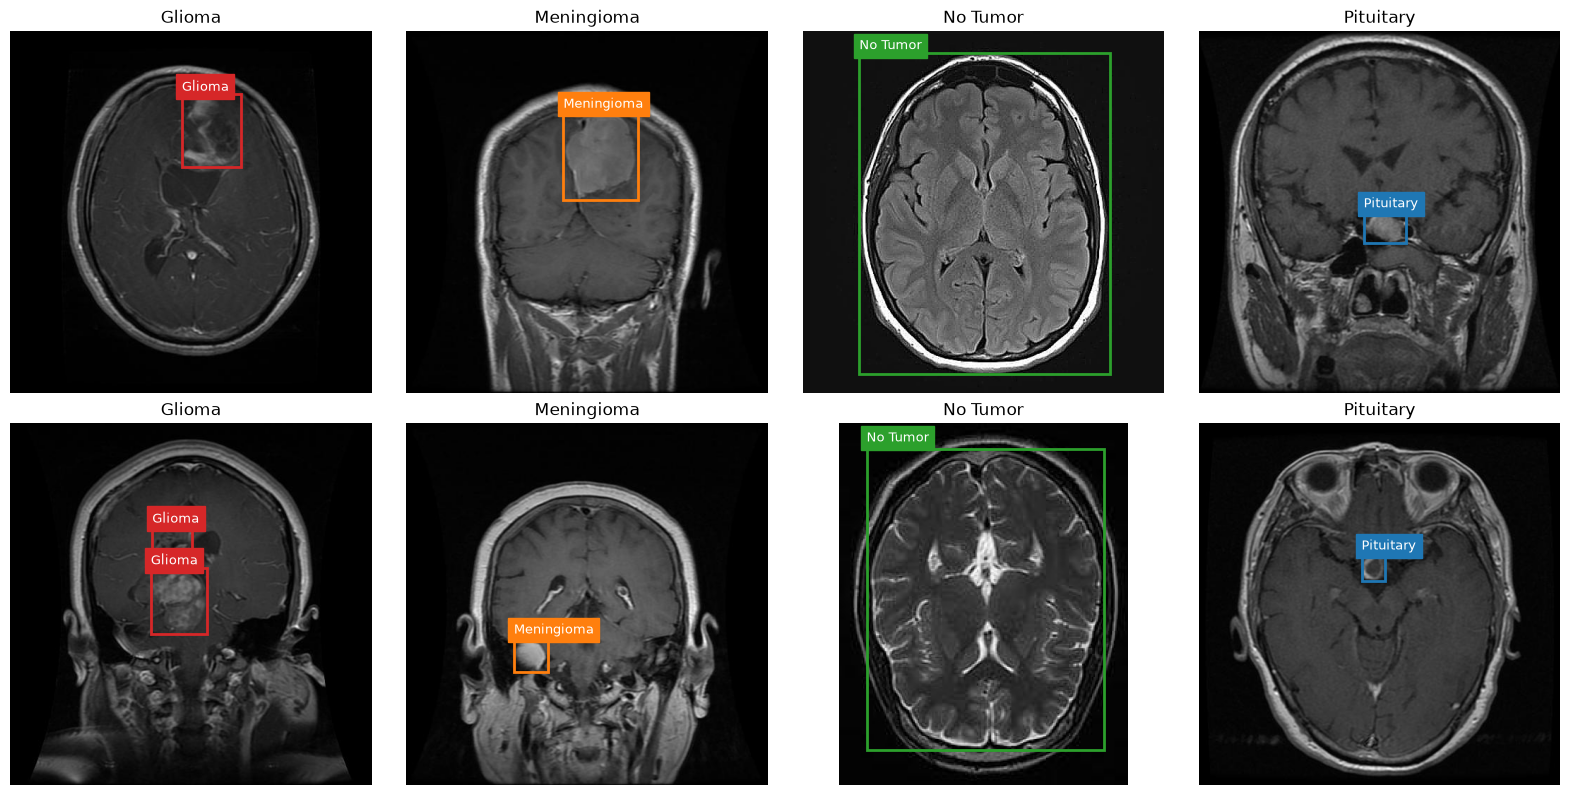

In [29]:
random.seed(42)
samples = []
for class_dir in sorted((DATA_DIR / "Train").iterdir()):
    images = sorted((class_dir / "images").glob("*.jpg"))
    for image_path in random.sample(images, 2):
        samples.append((image_path, class_dir / "labels" / f"{image_path.stem}.txt"))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (image_path, label_path) in zip(axes.T.flat, samples):
    draw_boxes(ax, image_path, label_path)
    ax.set_title(image_path.parent.parent.name)
plt.tight_layout()
plt.show()

In [30]:
IMG_EXTS = {".jpg", ".jpeg", ".png"}

pairs, images_without_label, labels_without_image = [], [], []
for split_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        images = {f.stem: f for f in (class_dir / "images").iterdir() if f.suffix.lower() in IMG_EXTS}
        labels = {f.stem: f for f in (class_dir / "labels").iterdir() if f.suffix == ".txt"}
        pairs += [(images[name], labels[name]) for name in sorted(images.keys() & labels.keys())]
        images_without_label += [images[name] for name in sorted(images.keys() - labels.keys())]
        labels_without_image += [labels[name] for name in sorted(labels.keys() - images.keys())]

print(f"Paires valides : {len(pairs)}")
print(f"Images sans label : {len(images_without_label)}", [p.name for p in images_without_label])
print(f"Labels sans image : {len(labels_without_image)}", [p.name for p in labels_without_image])

Paires valides : 5247
Images sans label : 2 ['image(55).jpg', 'image(61).jpg']
Labels sans image : 2 ['image(53).txt', 'image(60).txt']


In [31]:
from collections import Counter

CLASS_IDS = {name: i for i, name in enumerate(CLASS_NAMES)}


def parse_line(line):
    parts = line.split()
    if len(parts) != 5:
        return None
    try:
        cls = int(parts[0])
        xc, yc, w, h = map(float, parts[1:])
    except ValueError:
        return None
    if not 0 <= cls < len(CLASS_NAMES):
        return None
    if not all(0 <= v <= 1 for v in (xc, yc, w, h)) or w <= 0 or h <= 0:
        return None
    return cls, xc, yc, w, h


clean_pairs = []
invalid_lines, inconsistent_files, discarded = [], [], []

for image_path, label_path in pairs:
    folder_class = CLASS_IDS[image_path.parent.parent.name]
    boxes = []
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        box = parse_line(line)
        if box is None:
            invalid_lines.append((label_path, line))
        else:
            boxes.append(box)

    if any(box[0] != folder_class for box in boxes):
        inconsistent_files.append((image_path, label_path))

    if any(box[0] == folder_class for box in boxes):
        clean_pairs.append((image_path, boxes))
    else:
        discarded.append(image_path)

print(f"Lignes invalides : {len(invalid_lines)}")
print(f"Fichiers avec une boîte d'une autre classe : {len(inconsistent_files)}",
      dict(Counter(p.parent.parent.name for p, _ in inconsistent_files)))
print(f"Images écartées (aucune boîte de leur classe) : {len(discarded)}", [p.name for p in discarded])
print(f"Paires propres : {len(clean_pairs)}")

Lignes invalides : 0
Fichiers avec une boîte d'une autre classe : 272 {'Glioma': 165, 'Meningioma': 106, 'Pituitary': 1}
Images écartées (aucune boîte de leur classe) : 16 ['Te-gl_0043.jpg', 'Tr-gl_1167.jpg', 'gg (278).jpg', 'Tr-me_0023.jpg', 'Tr-me_0119.jpg', 'Tr-me_0385.jpg', 'm (49).jpg', 'm (50).jpg', 'm (51).jpg', 'm (52).jpg', 'm (53).jpg', 'm (54).jpg', 'm (55).jpg', 'm3 (120).jpg', 'p (564).jpg', 'gg (342).jpg']
Paires propres : 5231


In [32]:
import shutil
import pandas as pd

YOLO_DIR = Path("../processed/yolo")
SET_NAMES = {"train": "train", "val": "valid", "test": "test"}

split_df = pd.read_csv("../processed/split.csv")
image_set = {Path(p).resolve(): SET_NAMES[s] for p, s in zip(split_df["path"], split_df["set"])}

shutil.rmtree(YOLO_DIR, ignore_errors=True)
for image_path, boxes in clean_pairs:
    set_name = image_set[image_path.resolve()]
    label_path = image_path.parent.parent / "labels" / f"{image_path.stem}.txt"
    for kind, src in [("images", image_path), ("labels", label_path)]:
        dest = YOLO_DIR / kind / set_name
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dest / src.name)

In [33]:
counts = pd.DataFrame({
    kind: {set_name: len(list((YOLO_DIR / kind / set_name).iterdir())) for set_name in SET_NAMES.values()}
    for kind in ["images", "labels"]
})
counts.loc["total"] = counts.sum()
counts

,images,labels
train,3660,3660
valid,786,786
test,785,785
total,5231,5231


In [34]:
import yaml 

DATA_YAML = YOLO_DIR / 'data.yaml'

data_config = {
    'path': str(YOLO_DIR.resolve()),
    'train': 'images/train',
    'val': 'images/valid',
    'test': 'images/test',
    'nc': len(CLASS_NAMES),
    'names':CLASS_NAMES,
}

DATA_YAML.write_text(yaml.safe_dump(data_config , sort_keys=False , allow_unicode=True))
print(DATA_YAML.read_text())

path: /home/kerymy/Study-DevAI/DiagnosticMultimodal/processed/yolo
train: images/train
val: images/valid
test: images/test
nc: 4
names:
- Glioma
- Meningioma
- No Tumor
- Pituitary



In [35]:
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()

with open(PROJECT_ROOT / 'config' / 'detection.yaml') as f:
    det_config = yaml.safe_load(f)
    
model_name = det_config.pop('model')
det_config["data"] = str(PROJECT_ROOT / det_config["data"])

print(model_name)
det_config

yolov8n.pt


{'data': '/home/kerymy/Study-DevAI/DiagnosticMultimodal/processed/yolo/data.yaml',
 'imgsz': 512,
 'epochs': 50,
 'patience': 10,
 'batch': 16,
 'optimizer': 'auto',
 'lr0': 0.01,
 'seed': 42,
 'deterministic': True,
 'hsv_h': 0.0,
 'hsv_s': 0.0,
 'hsv_v': 0.3,
 'degrees': 10.0,
 'translate': 0.1,
 'scale': 0.3,
 'fliplr': 0.5,
 'flipud': 0.0,
 'mosaic': 1.0,
 'close_mosaic': 10,
 'mixup': 0.0}

In [36]:
import contextlib
import os

import mlflow
from ultralytics import YOLO, settings

EXPERIMENT = "brain-tumor-detection"
os.environ["MLFLOW_TRACKING_URI"] = f"sqlite:///{PROJECT_ROOT / 'mlflow.db'}"
os.environ["MLFLOW_EXPERIMENT_NAME"] = EXPERIMENT
settings.update({"mlflow": True})

mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(PROJECT_ROOT / "mlruns").as_uri())

In [37]:
RUNS_DIR = PROJECT_ROOT / "runs" / "detect"

WEIGHTS_DIR = PROJECT_ROOT / "models" / "pretrained"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)


def train_yolo(weights):
    run_name = Path(weights).stem
    with contextlib.chdir(WEIGHTS_DIR):
        model = YOLO(weights)
        model.train(**det_config, project=str(RUNS_DIR), name=run_name, exist_ok=True)
    return RUNS_DIR / run_name


TRAIN_WEIGHTS = [model_name, "yolov8s.pt"]
run_dirs = {Path(weights).stem: train_yolo(weights) for weights in TRAIN_WEIGHTS}


New https://pypi.org/project/ultralytics/8.4.190 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.11.17 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 7891MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/kerymy/Study-DevAI/DiagnosticMultimodal/processed/yolo/data.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_

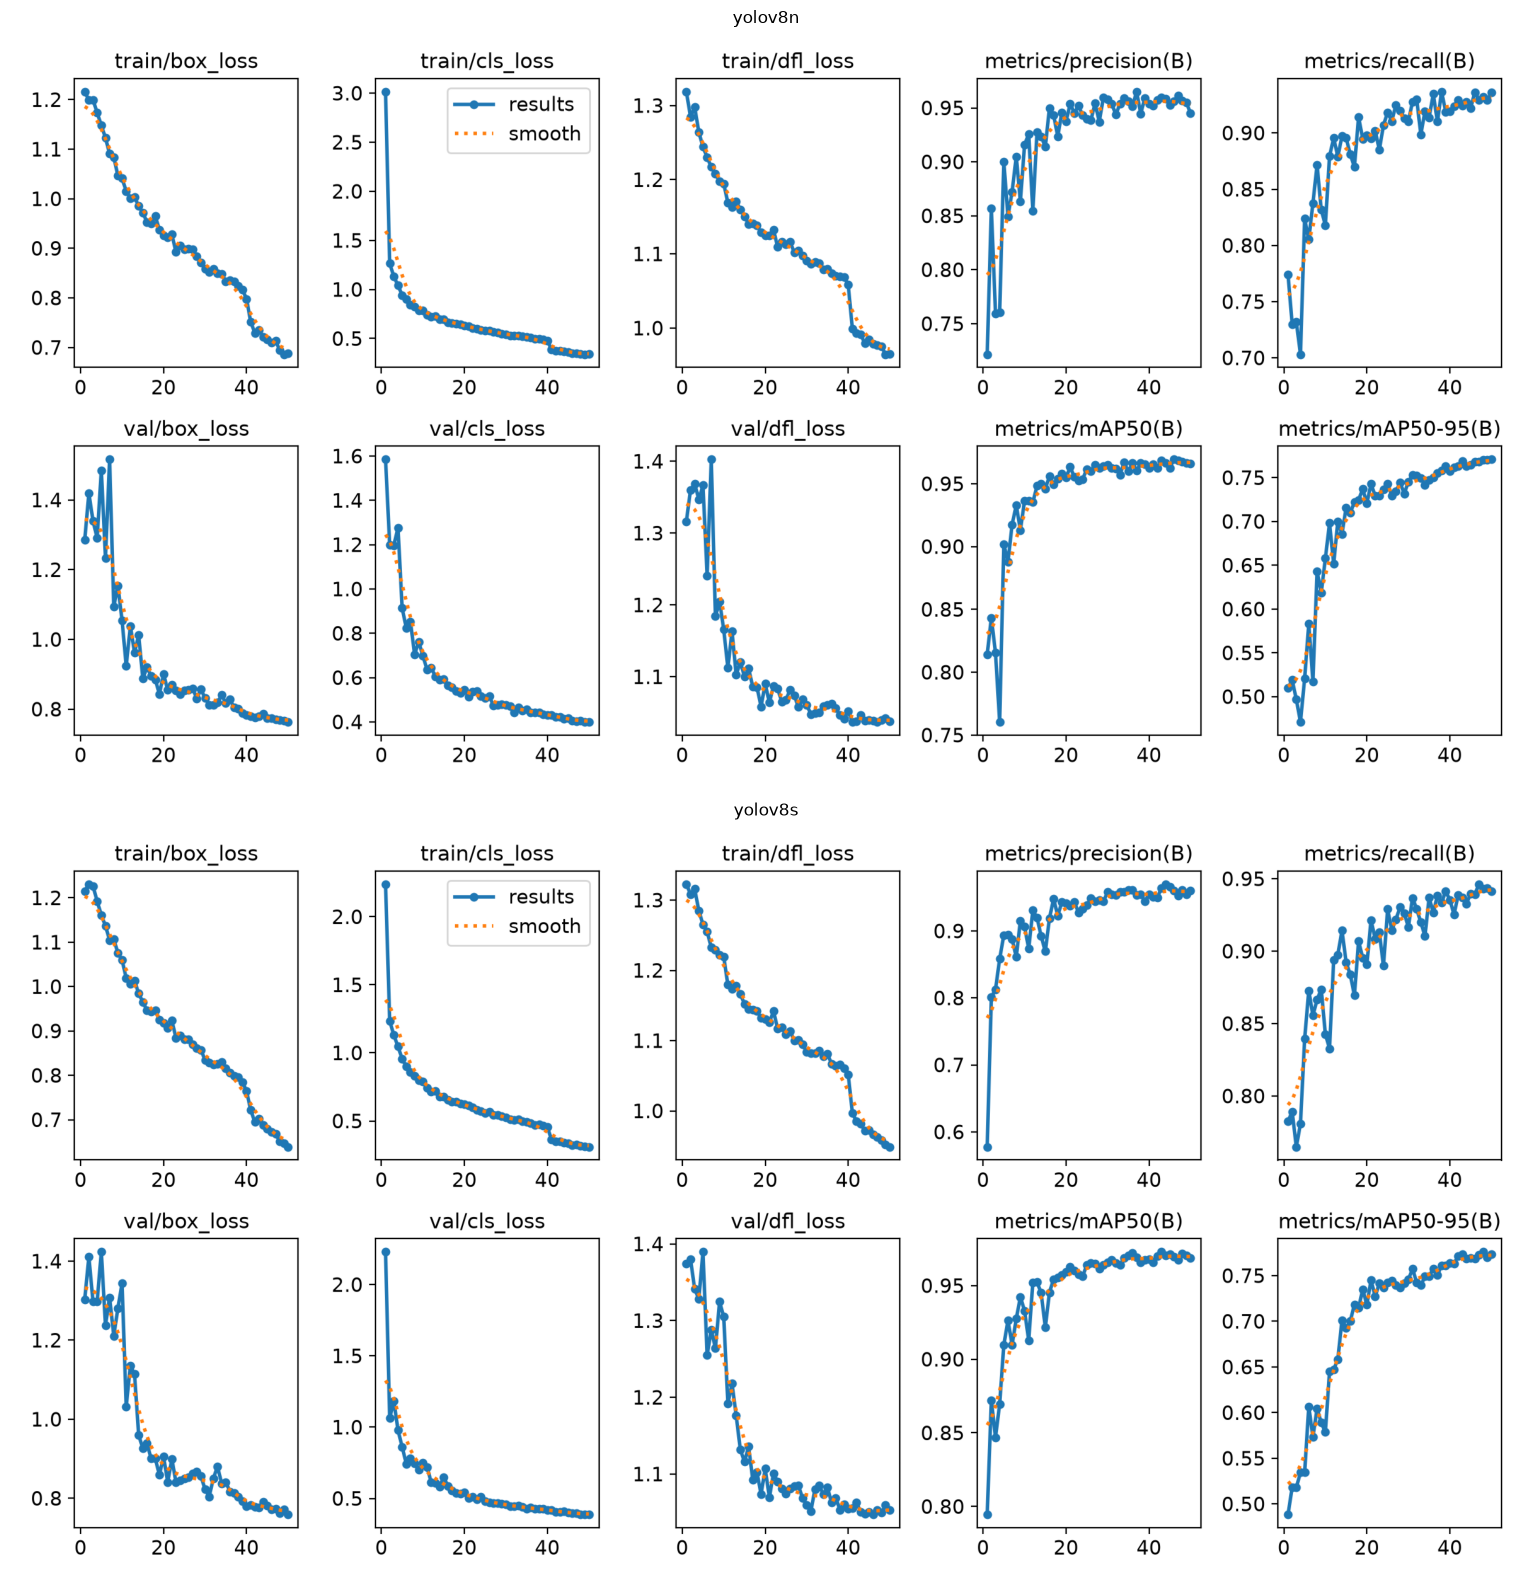

In [38]:
fig, axes = plt.subplots(len(run_dirs), 1, figsize=(16, 8 * len(run_dirs)))
for ax, (name, run_dir) in zip(axes, run_dirs.items()):
    ax.imshow(plt.imread(run_dir / "results.png"))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()